In [1]:
import pandas
import seaborn
from matplotlib import pyplot
from pandas.plotting import register_matplotlib_converters

from airpollutionforecasting.pipeline import run_pipeline
from airpollutionforecasting.eda.ts_correlation import TSCorrelationChecker

register_matplotlib_converters()
seaborn.set_style("darkgrid")

2026-11-20 20:35:40.849 | INFO     | airpollutionforecasting.config:<module>:18 - PROJ_ROOT path is: /home/pabito/Desktop/Projects/AirPolutionForecasting


In [2]:
pyplot.rc("figure", figsize=(16, 12))
pyplot.rc("font", size=13)

In [3]:
# run the pipeline to get the location of splitted files
split_files_locations = run_pipeline(stop_step="split")
# load the training data
data = pandas.read_csv(split_files_locations[0])
data["time"] = pandas.to_datetime(data["time"])

2026-11-20 20:35:45.049 | INFO     | airpollutionforecasting.pipeline:run_pipeline:28 - Running pipeline until split...
2026-11-20 20:35:45.051 | INFO     | airpollutionforecasting.data.loader:load:20 - Loading the data..
2026-11-20 20:35:45.141 | INFO     | airpollutionforecasting.data.data_validator:validate:149 - Starting data validation...
2026-11-20 20:35:45.142 | INFO     | airpollutionforecasting.data.data_validator:validate:151 - Checking required columns and data types...
2026-11-20 20:35:45.142 | SUCCESS  | airpollutionforecasting.data.data_validator:validate:153 - Column and data type validation passed.
2026-11-20 20:35:45.143 | INFO     | airpollutionforecasting.data.data_validator:validate:155 - Checking configured date range...
2026-11-20 20:35:45.144 | SUCCESS  | airpollutionforecasting.data.data_validator:validate:157 - Date range validation passed.
2026-11-20 20:35:45.144 | INFO     | airpollutionforecasting.data.data_validator:validate:159 - Checking for missing value

---
Lets observe PACF and ACF of the oryginal time series target (PM10 concetration)

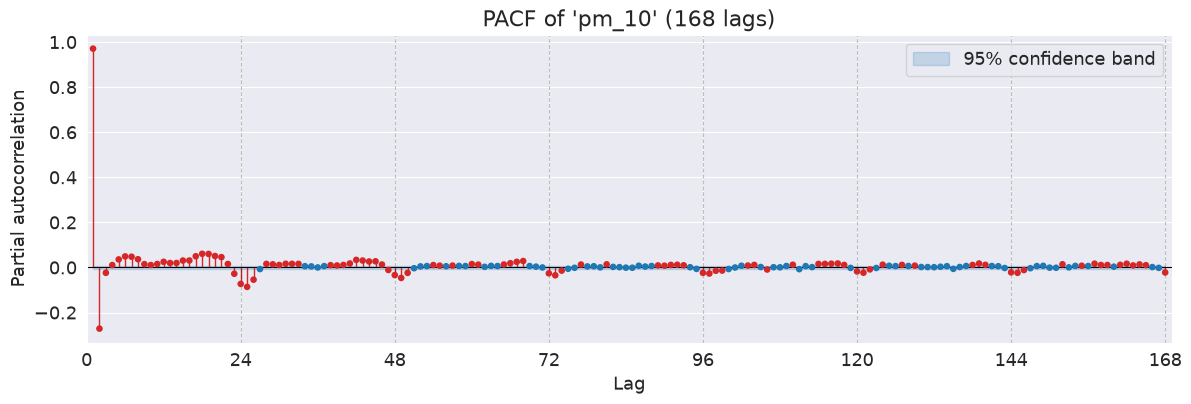

In [4]:
checker = TSCorrelationChecker(data, target_col="pm_10")

checker.plot_pacf_graph(
    nlags=168, seasonal_period=24
)  # daily guide lines every 24 lags
pyplot.show()

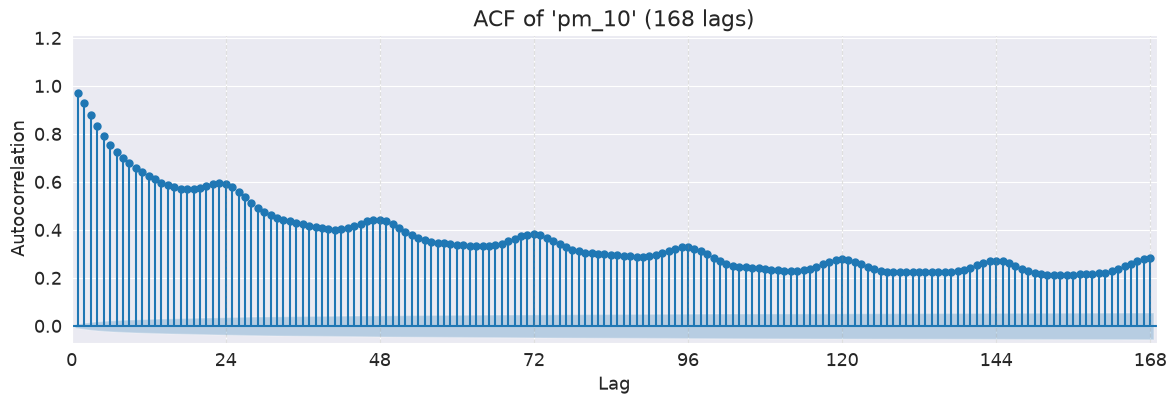

In [8]:
checker.plot_acf_graph(nlags=168)
pyplot.show()

---
### Differentiate the data to remove periodicity
Since we observe that correlations jump up every 24 hours, we can diffirientiate the 
time series to remove the effect of periodicity

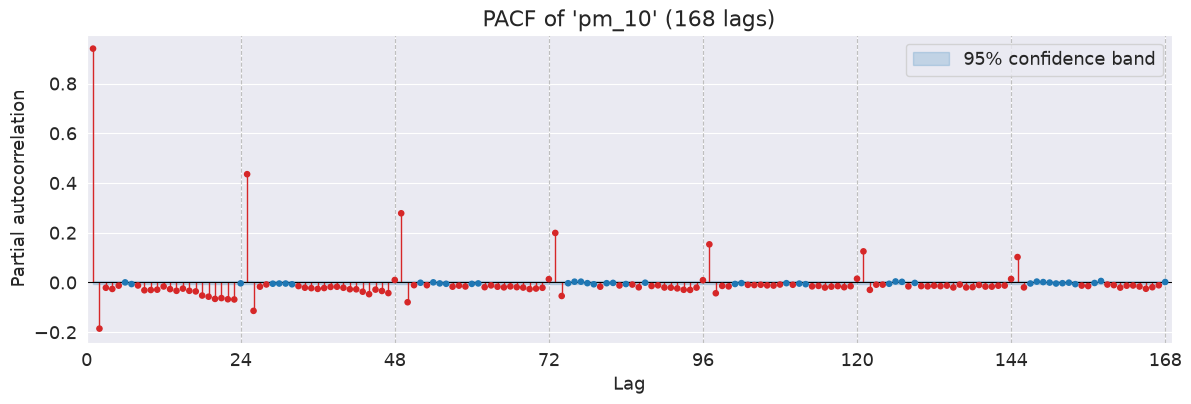

In [ ]:
#remove daily cycle from the data and copy to not influence oryginal data
daily_data = data['pm_10'].diff(24).dropna().copy()

# plot PACF with removed daily cycle
daily_checker = TSCorrelationChecker(daily_data, target_col="pm_10")
daily_checker.plot_pacf_graph(
    nlags=168, seasonal_period=24,
)  # daily guide lines every 24 lags
pyplot.show()

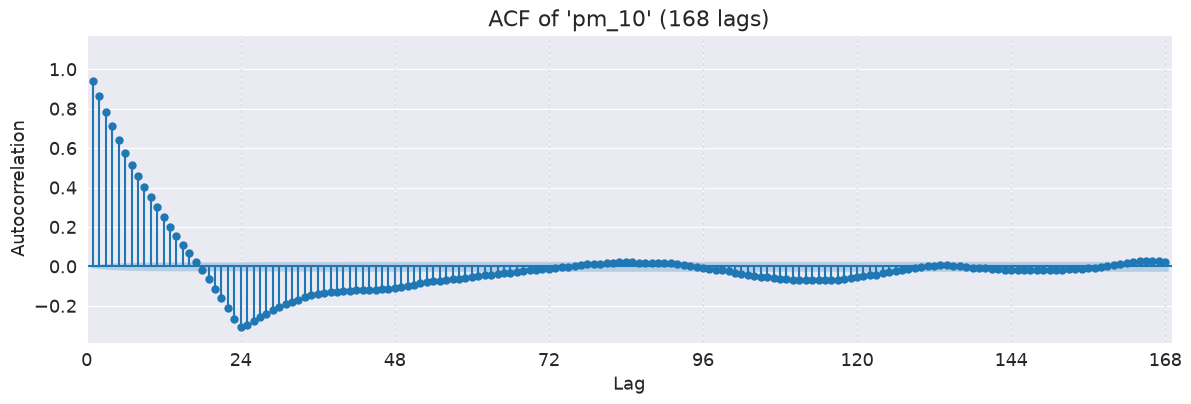

In [6]:
daily_checker.plot_acf_graph(nlags=168)
pyplot.show()

### Detrending the daily data
Since there is a trend that goes down in the data I will also check ACF after differentiation by 1. 
(DETRENDING)

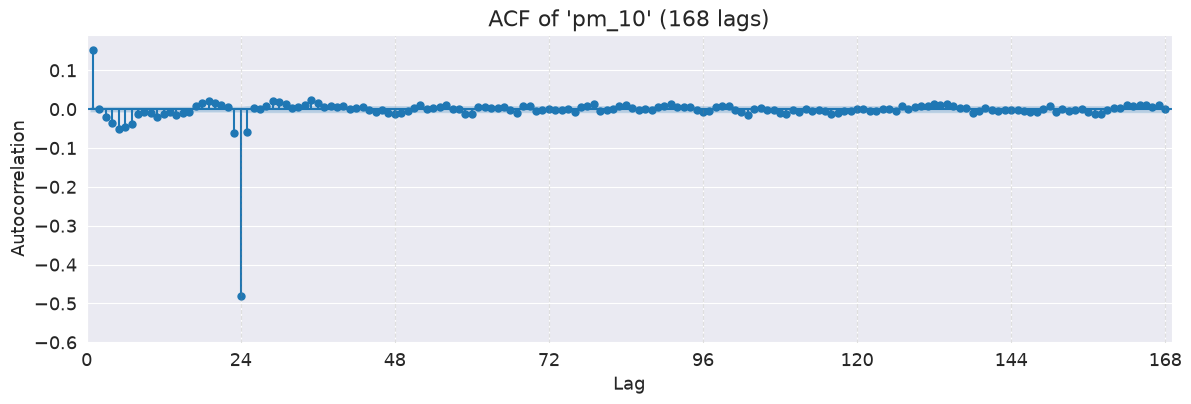

In [ ]:
#check the ACF for detrended data
daily_detrended_data = daily_data.diff(1).dropna()
daily_detrended_checker = TSCorrelationChecker(daily_detrended_data, target_col="pm_10")
daily_detrended_checker.plot_acf_graph(nlags=168)
pyplot.show()

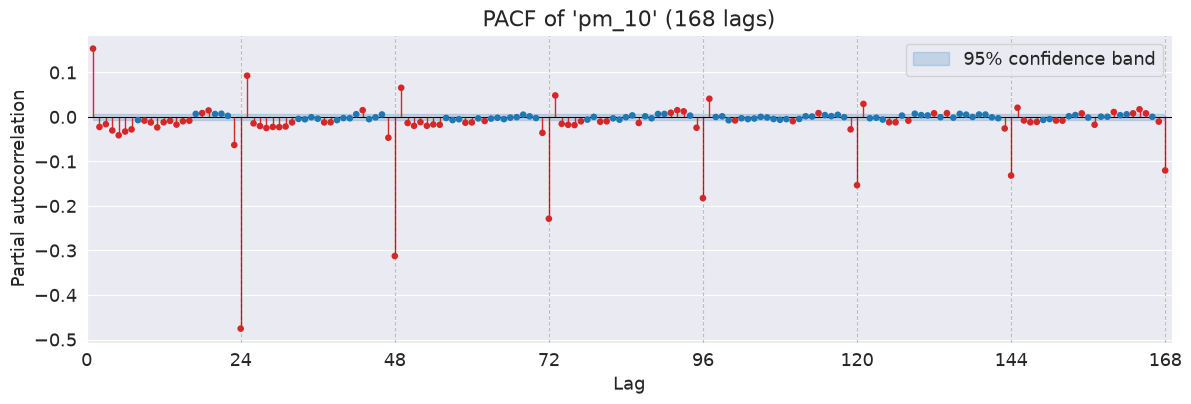

In [9]:
#plot PACF for fetrended data
daily_detrended_checker.plot_pacf_graph(
    nlags=168, seasonal_period=24,
)  # daily guide lines every 24 lags
pyplot.show()

---

### Observations
Lag 1 has ACF and PACF value of around 0.15.
After differencing at lag 24 and then at lag 1 we observe that most of the data is pure noise.
There is a single strong ACF spike at lag 24, and a PACF signal that slowly decays
across every 24 hours (24, 48, 72, ...).

This already gives us information about a possible SARIMAX model that could perform well:
`order = (p,d,q)`
- For p (AR order) a value of 1 may do the job, because of the lag 1 signal in the PACF.
- For d (differencing) we set the value 1, as we applied a lag-1 difference once.
- For q (MA order) I will also set the value of 1, because the lag 1 signal is also present
  in the ACF. The single lag 1 spike is ambiguous between AR and MA, so (1,1,1), (1,1,0)
  and (0,1,1) will be compared by AIC.

`seasonal_order = (P, D, Q, s)`
- s = 24 (season length)
- P = 0 (seasonal AR order), as the PACF does not cut off after lag 24 but decays
  across 24, 48, 72, ..., which is the signature of a seasonal MA term, not a seasonal AR term
- Q = 1 (seasonal MA order), as the ACF has a single spike at lag 24 and nothing at 48 or beyond
- D = 1 (seasonal differencing), as the lag-24 difference is applied once

The model is fitted on the raw series, as SARIMAX applies both differences internally.

---

In [7]:
ccf = checker.calculate_ccf(["air_temp", "relative_humidity", "wind_speed"], max_lag=72)

# Strongest lag per covariate
ccf.abs().idxmax()  # lag with the largest |correlation|
ccf.loc[ccf.abs().idxmax()]  # hmm, or simply:
ccf.apply(lambda s: s.loc[s.abs().idxmax()])  # its value

# Only lags usable by a past covariate with a 24h horizon
ccf.loc[24:]

# Same-time correlation (relevant for future covariates)
ccf.loc[0]

air_temp            -0.386207
relative_humidity    0.124240
wind_speed          -0.254733
Name: 0, dtype: float64

In [10]:
# Only lags usable by a past covariate with a 24h horizon
ccf.loc[24:]

,air_temp,relative_humidity,wind_speed
lag,,,
24,-0.402383,0.104348,-0.186855
25,-0.406349,0.112245,-0.194082
26,-0.407891,0.115383,-0.198023
27,-0.406186,0.112139,-0.196935
28,-0.401095,0.102620,-0.189230
29,-0.393278,0.088186,-0.175300
30,-0.383845,0.070821,-0.157581
31,-0.374132,0.052648,-0.138241
32,-0.365257,0.035665,-0.119452


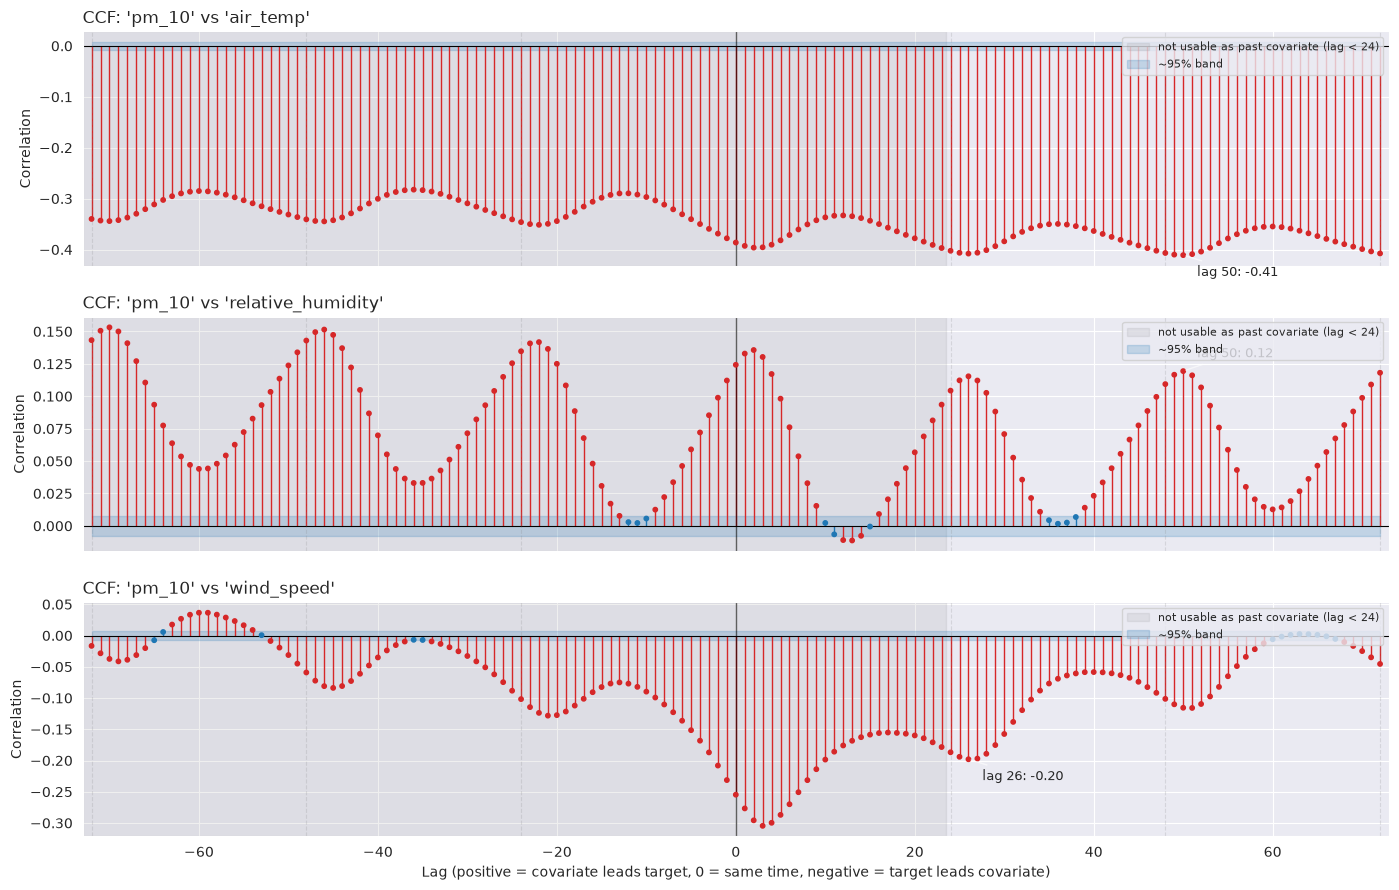

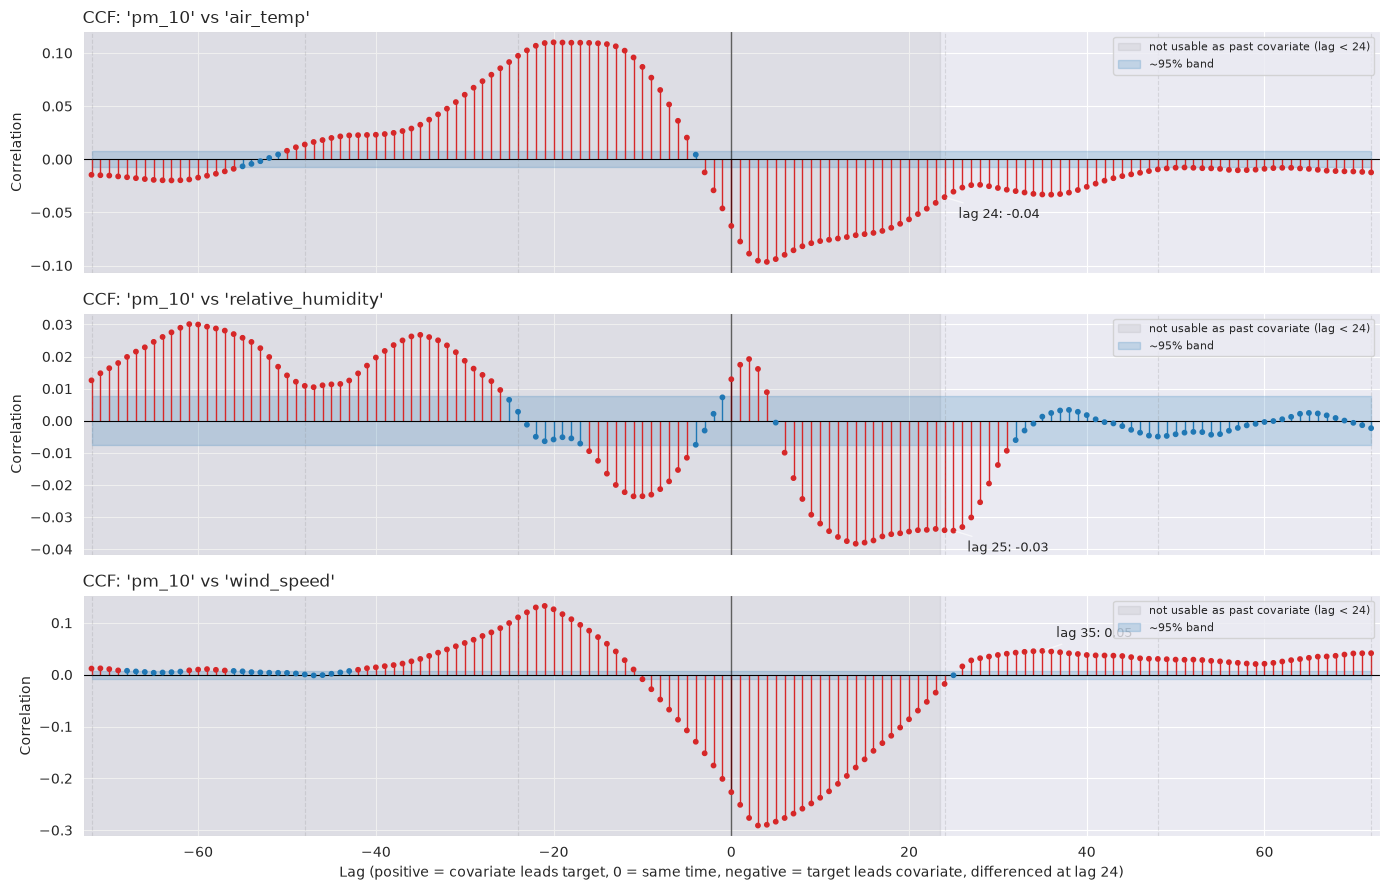

In [6]:
# Raw vs differenced, 24h forecast horizon
checker.plot_ccf(
    ["air_temp", "relative_humidity", "wind_speed"], max_lag=72, horizon=24
)
checker.plot_ccf(
    ["air_temp", "relative_humidity", "wind_speed"], max_lag=72, horizon=24, diff_lag=24
)
pyplot.show()